In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import STL
plt.style.use("seaborn-v0_8")


In [ ]:
df_ref = pd.read_csv("df_reference.csv")
df_ano = pd.read_csv("df_anomaly.csv")

# 处理时间索引
for df in [df_ref, df_ano]:
    df["Datetime"] = pd.to_datetime(df["Datetime"])
    df.set_index("Datetime", inplace=True)
    df.sort_index(inplace=True)

df_ref.head()


,WaterLevel(m),Flow(L/s),Velocity(m/s),WaterTemperature(_),Precipiation(mm),AirTemperature(_),RelativeHumidity(%),VaporPressure(kPa),WindSpeed(m/s),WindDirection
Datetime,,,,,,,,,,
2022-10-20 00:00:00,1.055,250.825,0.499,19.921,0.0,15.7,52.0,1018.0,0.0,0.0
2022-10-20 00:01:00,1.055,246.804,0.491,19.921,0.0,15.7,52.0,1018.0,0.0,0.0
2022-10-20 00:02:00,1.055,242.280,0.482,19.921,0.0,15.7,52.0,1018.0,0.0,0.0
2022-10-20 00:03:00,1.050,242.280,0.482,19.921,0.0,15.7,52.0,1018.0,0.0,0.0
2022-10-20 00:04:00,1.050,250.825,0.499,19.921,0.0,15.7,52.0,1018.0,0.0,0.0


In [ ]:
df_ref.index.to_series().diff().value_counts().head()

,count
Datetime,
0 days 00:01:00,31227
0 days 00:03:00,6
0 days 00:04:00,3
0 days 00:06:00,3
0 days 00:02:00,2


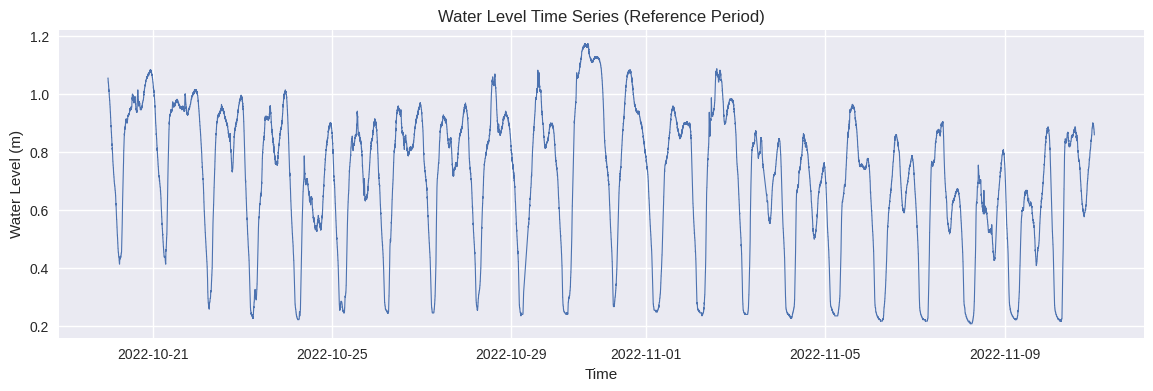

In [ ]:
plt.figure(figsize=(14,4))
plt.plot(df_ref.index, df_ref["WaterLevel(m)"], linewidth=0.8)
plt.title("Water Level Time Series (Reference Period)")
plt.xlabel("Time")
plt.ylabel("Water Level (m)")
plt.show()


In [ ]:
df_ref["hour"] = df_ref.index.hour



In [ ]:
hourly_stats = df_ref.groupby("hour")["WaterLevel(m)"].agg(["mean", "std"])
hourly_stats


,mean,std
hour,,
0,0.801181,0.138486
1,0.662756,0.149279
2,0.519192,0.176327
3,0.403473,0.167925
4,0.321539,0.135268
5,0.275542,0.086343
6,0.275688,0.063566
7,0.378512,0.112088
8,0.612925,0.144344


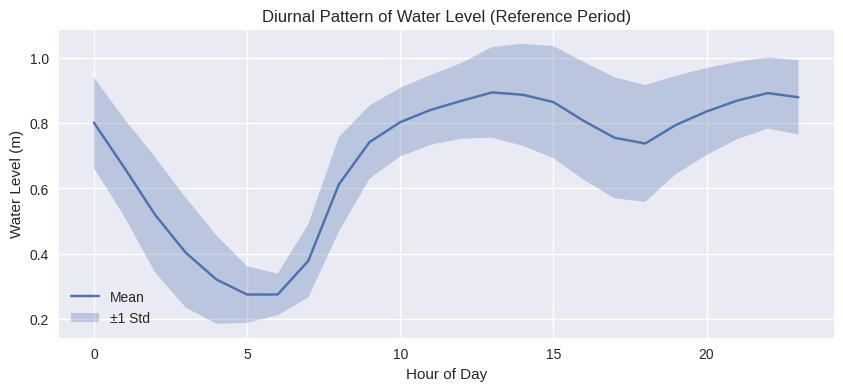

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(hourly_stats.index, hourly_stats["mean"], label="Mean")
plt.fill_between(
    hourly_stats.index,
    hourly_stats["mean"] - hourly_stats["std"],
    hourly_stats["mean"] + hourly_stats["std"],
    alpha=0.3,
    label="±1 Std"
)
plt.xlabel("Hour of Day")
plt.ylabel("Water Level (m)")
plt.title("Diurnal Pattern of Water Level (Reference Period)")
plt.legend()
plt.show()


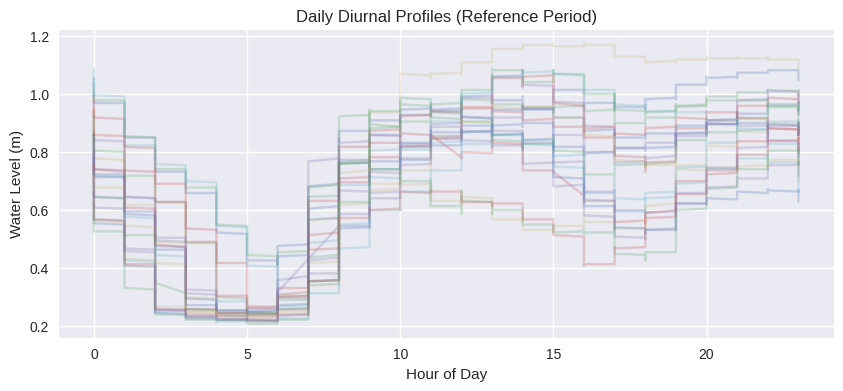

In [ ]:
df_ref["date"] = df_ref.index.date

plt.figure(figsize=(10,4))
for d, g in df_ref.groupby("date"):
    plt.plot(g["hour"], g["WaterLevel(m)"], alpha=0.25)

plt.xlabel("Hour of Day")
plt.ylabel("Water Level (m)")
plt.title("Daily Diurnal Profiles (Reference Period)")
plt.show()


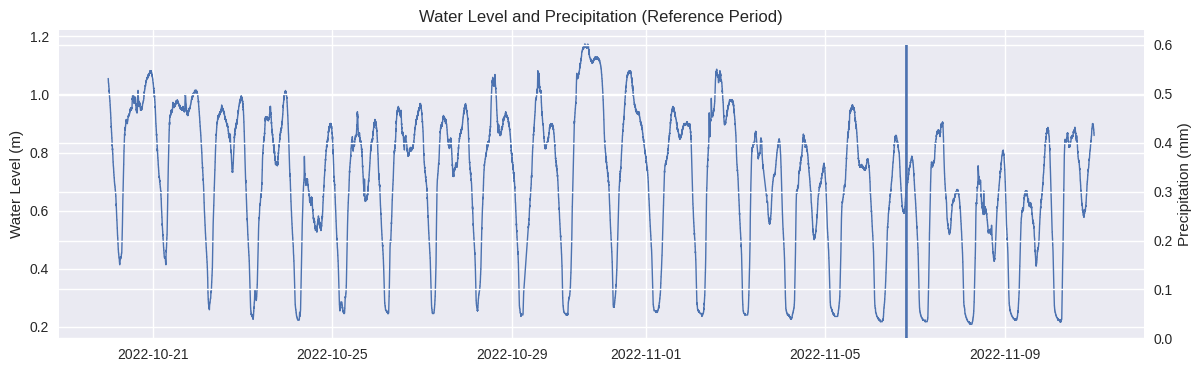

In [ ]:
fig, ax1 = plt.subplots(figsize=(14,4))

ax1.plot(df_ref.index, df_ref["WaterLevel(m)"], linewidth=1)
ax1.set_ylabel("Water Level (m)")

ax2 = ax1.twinx()
ax2.bar(df_ref.index, df_ref["Precipiation(mm)"],
        width=0.01, alpha=0.3)
ax2.set_ylabel("Precipitation (mm)")

plt.title("Water Level and Precipitation (Reference Period)")
plt.show()


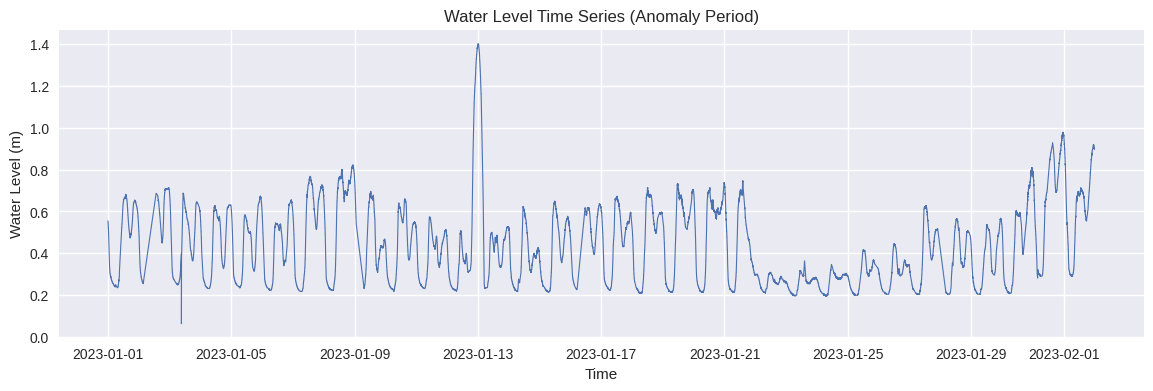

In [ ]:
plt.figure(figsize=(14,4))
plt.plot(df_ano.index, df_ano["WaterLevel(m)"], linewidth=0.8)
plt.title("Water Level Time Series (Anomaly Period)")
plt.xlabel("Time")
plt.ylabel("Water Level (m)")
plt.show()


In [ ]:
df_ano["hour"] = df_ano.index.hour
hourly_ano = df_ano.groupby("hour")["WaterLevel(m)"].mean()


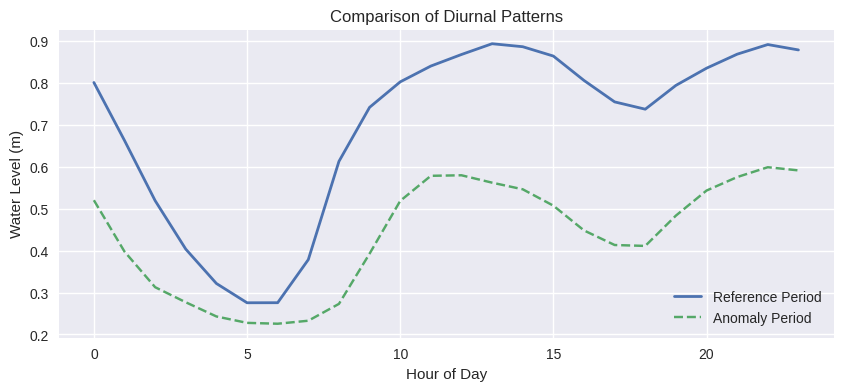

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(hourly_stats.index, hourly_stats["mean"],
         label="Reference Period", linewidth=2)
plt.plot(hourly_ano.index, hourly_ano.values,
         label="Anomaly Period", linestyle="--")
plt.xlabel("Hour of Day")
plt.ylabel("Water Level (m)")
plt.title("Comparison of Diurnal Patterns")
plt.legend()
plt.show()


In [ ]:
# 确保 hour 列存在
df_ref["hour"] = df_ref.index.hour

# 按小时构建 reference 模板
hourly_template = df_ref.groupby("hour")["WaterLevel(m)"].agg(
    mean="mean",
    std="std"
)

hourly_template


,mean,std
hour,,
0,0.801181,0.138486
1,0.662756,0.149279
2,0.519192,0.176327
3,0.403473,0.167925
4,0.321539,0.135268
5,0.275542,0.086343
6,0.275688,0.063566
7,0.378512,0.112088
8,0.612925,0.144344


In [ ]:
# 为 anomaly 数据添加 hour
df_ano["hour"] = df_ano.index.hour

# 合并 reference 模板
df_ano = df_ano.merge(
    hourly_template,
    left_on="hour",
    right_index=True,
    how="left"
)

# 计算 z-score
df_ano["z_score"] = (
    df_ano["WaterLevel(m)"] - df_ano["mean"]
) / df_ano["std"]

df_ano[["WaterLevel(m)", "mean", "std", "z_score"]].head()


,WaterLevel(m),mean,std,z_score
Datetime,,,,
2023-01-01 00:00:00,0.555,0.801181,0.138486,-1.777660
2023-01-01 00:01:00,0.550,0.801181,0.138486,-1.813765
2023-01-01 00:02:00,0.550,0.801181,0.138486,-1.813765
2023-01-01 00:03:00,0.550,0.801181,0.138486,-1.813765
2023-01-01 00:04:00,0.550,0.801181,0.138486,-1.813765


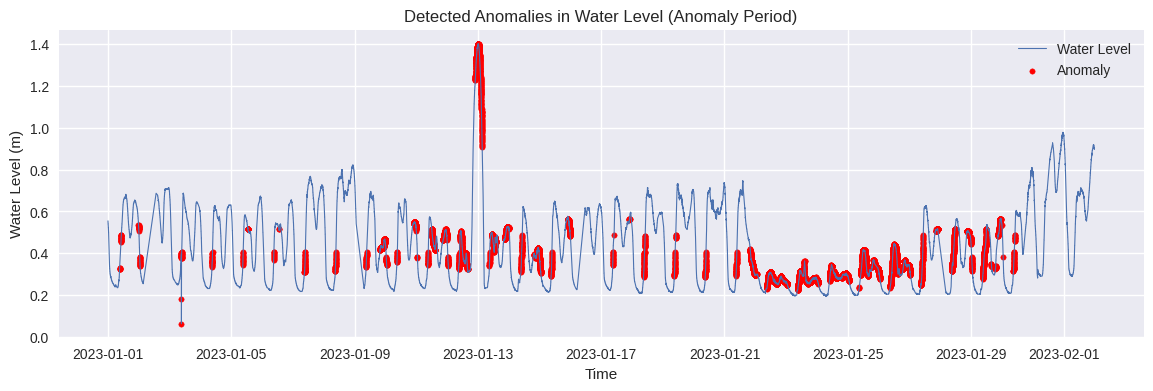

In [ ]:
plt.figure(figsize=(14,4))

plt.plot(
    df_ano.index,
    df_ano["WaterLevel(m)"],
    label="Water Level",
    linewidth=0.8
)

plt.scatter(
    df_ano.index[df_ano["is_anomaly"]],
    df_ano.loc[df_ano["is_anomaly"], "WaterLevel(m)"],
    color="red",
    label="Anomaly",
    s=15
)

plt.xlabel("Time")
plt.ylabel("Water Level (m)")
plt.title("Detected Anomalies in Water Level (Anomaly Period)")
plt.legend()
plt.show()


In [ ]:
# 设置阈值
Z_THRESHOLD = 3

# 标记异常
df_ano["is_anomaly"] = df_ano["z_score"].abs() > Z_THRESHOLD

# 查看异常数量
df_ano["is_anomaly"].value_counts()


,count
is_anomaly,
False,33412
True,7319


In [ ]:
# 连续异常点计数
df_ano["anomaly_group"] = (
    df_ano["is_anomaly"] != df_ano["is_anomaly"].shift()
).cumsum()

# 统计连续异常长度
group_sizes = df_ano[df_ano["is_anomaly"]].groupby("anomaly_group").size()

# 只保留连续 ≥ N 个点的异常
MIN_CONSECUTIVE = 3
valid_groups = group_sizes[group_sizes >= MIN_CONSECUTIVE].index

df_ano["is_anomaly_strict"] = (
    df_ano["is_anomaly"] & df_ano["anomaly_group"].isin(valid_groups)
)

df_ano["is_anomaly_strict"].value_counts()


,count
is_anomaly_strict,
False,33425
True,7306


In [ ]:
df_ano_out = df_ano[
    ["WaterLevel(m)", "z_score", "is_anomaly", "is_anomaly_strict"]
]

df_ano_out.to_csv("detected_anomalies.csv")
